# Supply Chain Analytics & Predictive Delivery Risk Pipeline
### End-to-End Operational Bottleneck Diagnosis, Profitability Impact, and Pre-Dispatch SLA Prediction

**Business Problem & Context**
A global ecommerce and retail logistics company operating across multiple international regions manages end-to-end order fulfillment for sporting goods, apparel, and consumer merchandise. The company faces inconsistent delivery performance where actual shipping times frequently deviate from promised schedules, leading to customer churn, negative reviews, and profit erosion.

**Desired Outcome**
Analyze end-to-end fulfillment operations, diagnose root-cause bottlenecks across carriers and regions, evaluate margin exposure, and deploy a machine learning model to predict late delivery risk at order confirmation.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings

filterwarnings('ignore')

In [2]:
# Set professional visual theme
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")
viridis_colors = cm.viridis(np.linspace(0, 1, 5))
primary_color = viridis_colors[0]
secondary_color = viridis_colors[1]
accent_color = viridis_colors[2]
danger_color = '#800000'
neutral_color = viridis_colors[4]
custom_palette = viridis_colors

In [3]:
# Load dataset with automatic path resolution
dataset_path = 'archive/DataCoSupplyChainDataset.csv' if os.path.exists('archive/DataCoSupplyChainDataset.csv') else 'DataCoSupplyChainDataset.csv'
df = pd.read_csv(dataset_path, encoding='latin-1')
print(f"Dataset successfully loaded from: {dataset_path}")
print(f"Raw shape: {df.shape[0]:,} rows, {df.shape[1]} columns")

Dataset successfully loaded from: archive/DataCoSupplyChainDataset.csv
Raw shape: 180,519 rows, 53 columns


In [4]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

## 1. Exploratory Data Analysis (EDA)
Inspect dataset dimensions, duplicate rows, missing values, and high-level column attributes.

In [5]:
print('Rows, Columns:', df.shape)
print('\nTotal Duplicate Rows:', df.duplicated().sum())
print('\nMissing Values (Top 20 Columns):')
print(df.isna().sum().sort_values(ascending=False).head(20))

Rows, Columns: (180519, 53)



Total Duplicate Rows: 0

Missing Values (Top 20 Columns):
Product Description         180519
Order Zipcode               155679
Customer Lname                   8
Customer Zipcode                 3
Type                             0
Order Profit Per Order           0
Order Item Cardprod Id           0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Id                    0
Order Item Product Price         0
Order Item Profit Ratio          0
Order Item Quantity              0
Sales                            0
Order Item Total                 0
Order Region                     0
order date (DateOrders)          0
Order State                      0
Order Status                     0
Product Card Id                  0
dtype: int64


In [6]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 2. Data Cleaning & Feature Selection Rationale
To ensure the analytical model focuses purely on operational fulfillment and delivery delay factors, we systematically inspect the 53 columns in batches of 20 to eliminate redundant, PII, and zero-variance attributes.

In [7]:
# Inspecting first 20 columns
first_20 = list(df.columns[:20])
print("First 20 columns:\n", first_20)
df[first_20].head(3)

First 20 columns:
 ['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode']


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0


**Observations on Columns 1–20:**
Customer credentials and personal identifiable information (PII) such as `Customer Email`, `Customer Password`, `Customer Fname`, `Customer Lname`, and `Customer Street` do not influence delivery transit time. Similarly, internal IDs like `Category Id` and `Customer Id` provide no variance beyond their descriptive text fields.

In [8]:
# Inspecting columns 20 to 40
second_20 = list(df.columns[20:40])
print("Columns 20-40:\n", second_20)
df[second_20].head(3)

Columns 20-40:
 ['Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order']


,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order
0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000
1,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996
2,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999


In [9]:
# Inspecting remaining columns 40+
remaining_cols = list(df.columns[40:])
print("Remaining columns:\n", remaining_cols)
df[remaining_cols].head(3)

Remaining columns:
 ['Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrders)', 'Shipping Mode']


,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class


In [10]:
# Consolidated list of 33 redundant, PII, and non-informative columns
columns_to_drop = [
    'Product Description', 'Product Image', 'Customer Email', 'Customer Password',
    'Customer Fname', 'Customer Lname', 'Customer Street', 'Customer Zipcode',
    'Order Zipcode', 'Latitude', 'Longitude', 'Order Item Cardprod Id',
    'Order Item Id', 'Order Item Discount', 'Order Item Discount Rate',
    'Order Item Product Price', 'Order Item Quantity', 'Order Item Total',
    'Category Id', 'Department Id', 'Order Id', 'Order Customer Id',
    'Customer Id', 'Product Card Id', 'Product Category Id',
    'Benefit per order', 'Product Status', 'Customer City', 'Order City',
    'Order Country', 'Order State', 'Customer State', 'Market'
]

# Drop redundant columns
df = df.drop(columns=columns_to_drop, errors='ignore')

# Remove canceled orders as they do not reach active delivery completion
df = df[df['Delivery Status'] != 'Shipping canceled']

# Standardize date format
for c in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    df[c] = pd.to_datetime(df[c], errors='coerce')

print("Shape after data cleansing & filtering canceled orders:", df.shape)
print("\nMissing values in cleaned dataset (Top 5):")
print(df.isna().sum().sort_values(ascending=False).head(5))

Shape after data cleansing & filtering canceled orders: (172765, 20)

Missing values in cleaned dataset (Top 5):
Type                          0
Days for shipping (real)      0
shipping date (DateOrders)    0
Product Price                 0
Product Name                  0
dtype: int64


In [11]:
# Value counts for categorical columns with low cardinality (< 10 distinct values)
for col in df.columns:
    if df[col].nunique() < 10:
        print(f"\n--- {col} Value Counts ---")
        print(df[col].value_counts())


--- Type Value Counts ---
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

--- Days for shipping (real) Value Counts ---
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

--- Days for shipment (scheduled) Value Counts ---
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

--- Delivery Status Value Counts ---
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

--- Late_delivery_risk Value Counts ---
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

--- Customer Country Value Counts ---
Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

--- Customer Segment Value Counts ---
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

-

## 3. Feature Engineering: Latency, Delay & Profitability
We construct operational metrics to quantify fulfillment performance:
- **Order Processing Time**: Elapsed days from order placement to carrier dispatch.
- **Delay (Days)**: Processing time minus scheduled delivery window.
- **Is_Delayed**: Binary flag indicating whether the order breached scheduled SLA (`Delay > 0`).
- **Profitability Flag**: Categorizes orders into `Profit`, `Loss`, or `Break-even`.

In [12]:
# Calculating processing time, delay duration, and temporal features
df['Order Processing Time'] = (df['shipping date (DateOrders)'] - df['order date (DateOrders)']).dt.days
df['Delay'] = df['Order Processing Time'] - df['Days for shipment (scheduled)']
df['Is_Delayed'] = df['Delay'] > 0
df['is_delayed'] = df['Is_Delayed']  # alias for compatibility
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.day_name()
df['order_hour'] = df['order date (DateOrders)'].dt.hour

# Profitability Flag based on Order Profit Per Order
df['Profitability Flag'] = np.where(
    df['Order Profit Per Order'] > 0, 'Profit',
    np.where(df['Order Profit Per Order'] < 0, 'Loss', 'Break-even')
)

print("Is_Delayed Distribution:")
print(df['Is_Delayed'].value_counts())
print("\nProfitability Flag Distribution:")
print(df['Profitability Flag'].value_counts(normalize=True).round(4) * 100)

Is_Delayed Distribution:
Is_Delayed
True     94523
False    78242
Name: count, dtype: int64

Profitability Flag Distribution:
Profitability Flag
Profit        80.66
Loss          18.69
Break-even     0.65
Name: proportion, dtype: float64


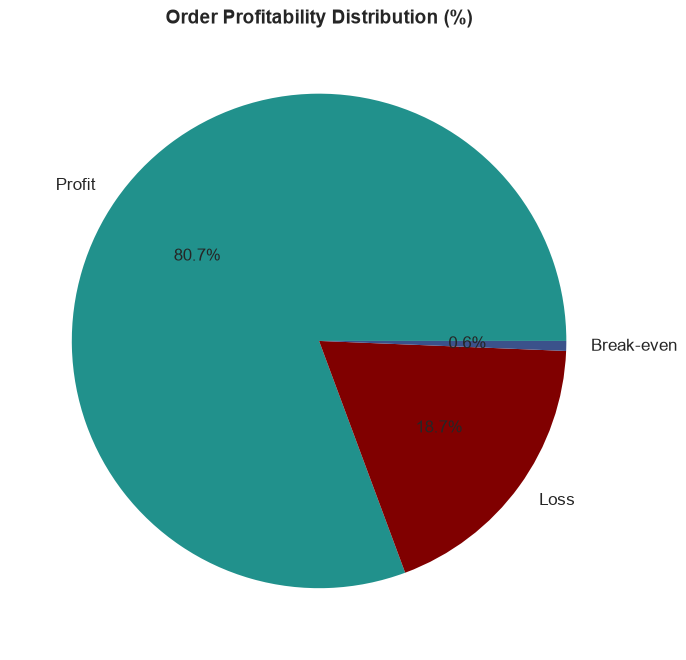

In [13]:
# Visualization of Profitability Distribution
profit_counts = df['Profitability Flag'].value_counts(normalize=True) * 100

color_map = {
    'Profit': accent_color,
    'Loss': danger_color,
    'Break-even': secondary_color
}
colors = [color_map[label] for label in profit_counts.index]

plt.figure(figsize=(7, 7))
profit_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=colors,
    textprops={'fontsize': 12}
)
plt.ylabel('')
plt.title('Order Profitability Distribution (%)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Business KPIs & Financial Exposure Scorecard
Quantify fulfillment reliability, delay percentiles, and gross margin tied up in delayed shipments.

In [14]:
def format_func(value):
    if value >= 1e6:
        return f'{value/1e6:.1f}M $'
    elif value >= 1e3:
        return f'{value/1e3:.1f}K $'
    else:
        return f'{value:.0f} $'

delayed_df = df[df['Delay'] > 0]
metrics = {}
metrics['Total Orders'] = len(df)
metrics['Late Deliveries'] = len(delayed_df)
metrics['90% Delay (days)'] = delayed_df['Delay'].quantile(0.90)
metrics['On-Time Delivery %'] = (1.0 - float(metrics['Late Deliveries']) / metrics['Total Orders']) * 100
metrics['Late Delivery %'] = float(metrics['Late Deliveries']) / metrics['Total Orders'] * 100
metrics['Total Profit'] = format_func(df.loc[df['Order Profit Per Order'] > 0, 'Order Profit Per Order'].sum())
metrics['Total Loss due to delays'] = format_func(df.loc[df['Delay'] > 0, 'Order Profit Per Order'].sum())

print('\n================= BUSINESS KPIS SCORECARD =================\n')
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"  {k:30s}: {v:.2f}")
    else:
        print(f"  {k:30s}: {v}")
print('\n===========================================================\n')


================= BUSINESS KPIS SCORECARD =================

  Total Orders                  : 172765
  Late Deliveries               : 94523
  90% Delay (days)              : 3.00
  On-Time Delivery %            : 45.29
  Late Delivery %               : 54.71
  Total Profit                  : 7.5M $
  Total Loss due to delays      : 2.1M $




## 5. Profitability vs. Delivery Time Analysis
Assess order frequency across delay increments and observe how average and total profits vary across delayed cohorts.

In [15]:
profit_metrics = (
    df.groupby('Delay')['Order Profit Per Order']
    .agg(mean_profit='mean', total_profit='sum', order_count='count')
    .reset_index()
)

delay_distribution = (
    df['Delay']
    .value_counts(normalize=True)
    .sort_index() * 100
).reset_index()
delay_distribution.columns = ['Delay_Days', 'Percentage']

print("Profit Metrics by Delay Day:")
display(profit_metrics.round(2))

print("\nDelay Distribution (%):")
display(delay_distribution.round(2))

Profit Metrics by Delay Day:


,Delay,mean_profit,total_profit,order_count
0,-2,23.36,487596.07,20873
1,-1,21.60,447629.21,20719
2,0,22.25,815430.19,36650
3,1,22.33,1194894.65,53503
4,2,21.13,582111.05,27551
5,3,20.03,135652.72,6772
6,4,21.37,143106.74,6697



Delay Distribution (%):


,Delay_Days,Percentage
0,-2,12.08
1,-1,11.99
2,0,21.21
3,1,30.97
4,2,15.95
5,3,3.92
6,4,3.88


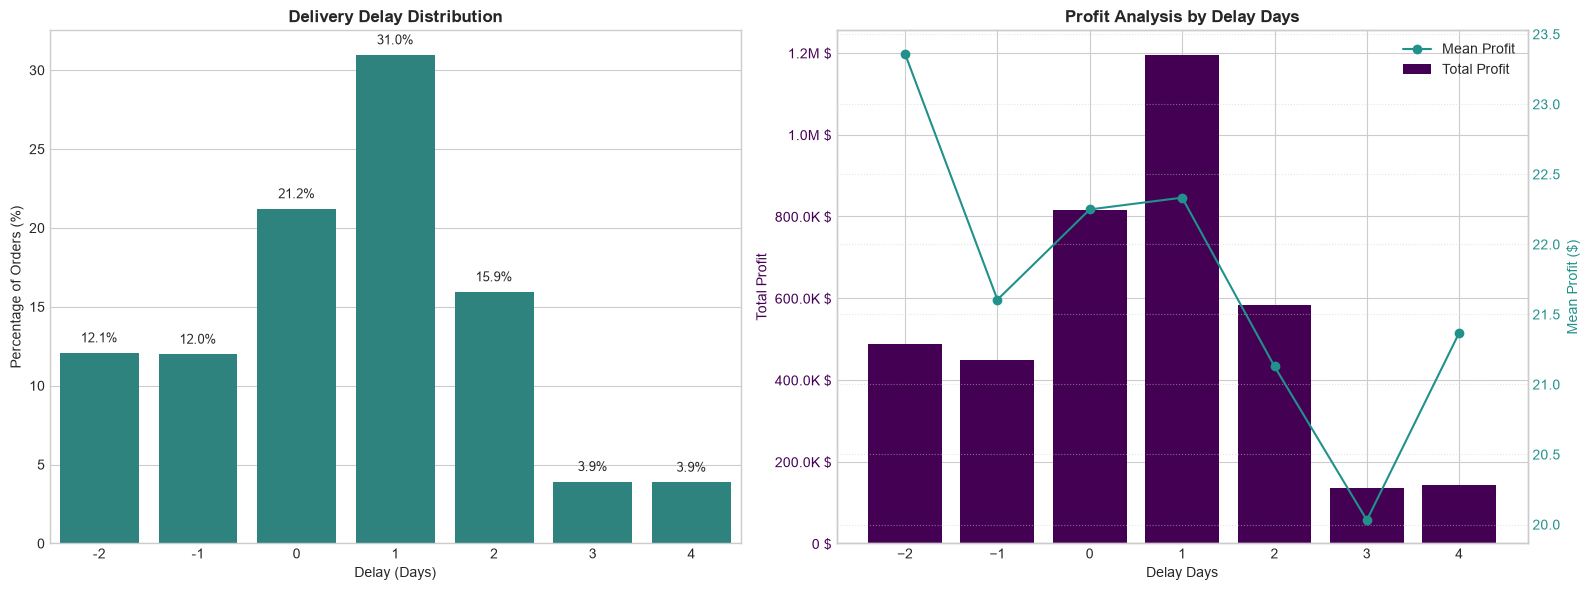

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Delay Distribution
sns.barplot(
    x='Delay_Days',
    y='Percentage',
    data=delay_distribution,
    color=accent_color,
    ax=ax1
)
ax1.set_title('Delivery Delay Distribution', fontsize=12, fontweight='bold')
ax1.set_xlabel('Delay (Days)')
ax1.set_ylabel('Percentage of Orders (%)')

for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=9
    )

# Subplot 2: Total & Mean Profit Analysis
ax2.set_xlabel("Delay Days")
ax2.set_ylabel("Total Profit", color=primary_color)
ax2.bar(
    profit_metrics['Delay'],
    profit_metrics['total_profit'],
    color=primary_color,
    label='Total Profit'
)
ax2.tick_params(axis='y', labelcolor=primary_color)

ax3 = ax2.twinx()
ax3.set_ylabel("Mean Profit ($)", color=accent_color)
ax3.plot(
    profit_metrics['Delay'],
    profit_metrics['mean_profit'],
    marker='o',
    color=accent_color,
    label='Mean Profit'
)
ax3.tick_params(axis='y', labelcolor=accent_color)

def format_ticks(value, tick_number):
    if value >= 1e6:
        return f'{value/1e6:.1f}M $'
    elif value >= 1e3:
        return f'{value/1e3:.1f}K $'
    else:
        return f'{value:.0f} $'

ax2.yaxis.set_major_formatter(ticker.FuncFormatter(format_ticks))
ax3.set_title("Profit Analysis by Delay Days", fontsize=12, fontweight='bold')

lines, labels = ax3.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax3.legend(lines + lines2, labels + labels2, loc='upper right')
ax3.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

## 6. Bottleneck Detection across Operational Dimensions
Evaluate delay percentage across Region, Customer Segment, Shipping Mode, Order Status, Transaction Type, and Product Department.

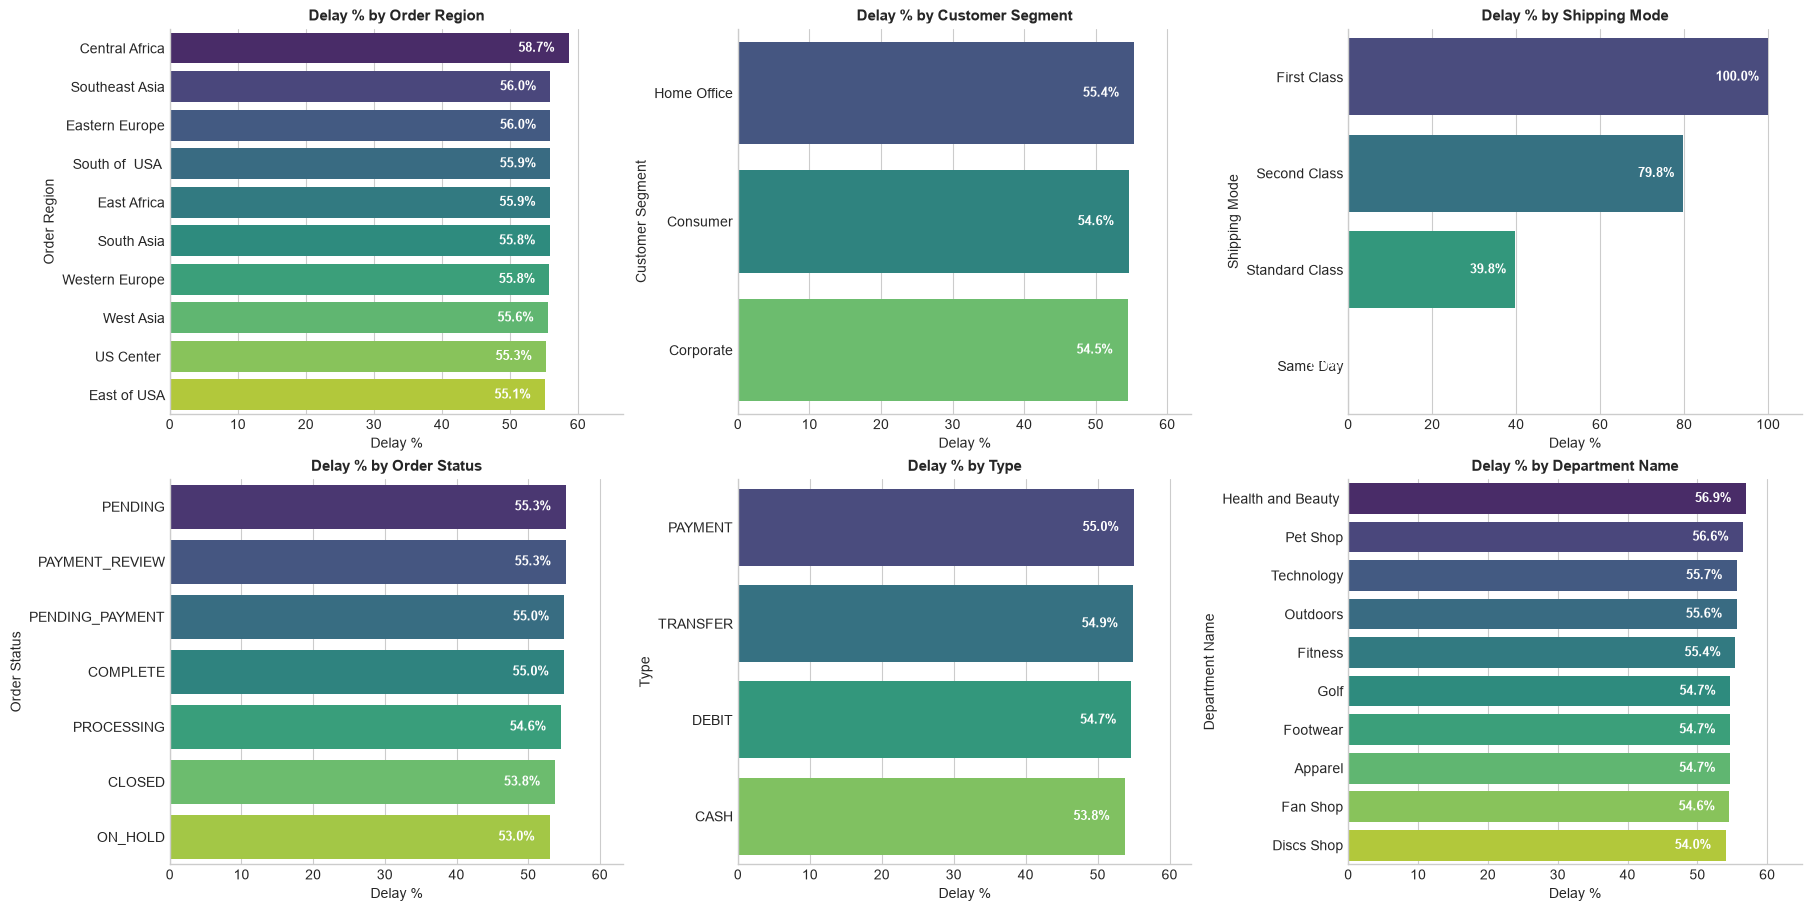

In [17]:
def compute_delay_pct_by_category(category):
    cat_df = df.groupby(category).agg(
        total_orders=('Delay', 'count'),
        late_orders=('Is_Delayed', 'sum')
    ).reset_index()
    cat_df['delay_pct'] = (cat_df['late_orders'] / cat_df['total_orders']) * 100
    cat_df = cat_df.sort_values('delay_pct', ascending=False).head(10)
    return cat_df

categories = [
    'Order Region',
    'Customer Segment',
    'Shipping Mode',
    'Order Status',
    'Type',
    'Department Name'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
axes = axes.flatten()

for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_by_category(category)

    sns.barplot(
        data=cat_df,
        x='delay_pct',
        y=category,
        ax=ax,
        palette='viridis'
    )
    ax.set_title(f'Delay % by {category}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Delay %')
    ax.set_ylabel(category)
    ax.set_xlim(0, cat_df['delay_pct'].max() + 8)

    for i, row in cat_df.reset_index().iterrows():
        ax.text(
            row['delay_pct'] - 2,
            i,
            f"{row['delay_pct']:.1f}%",
            va='center',
            ha='right',
            fontsize=9,
            color='white',
            fontweight='bold'
        )
    ax.spines[['top', 'right']].set_visible(False)

plt.show()

### Deep Dive: Shipping Mode & Order Status Anomalies
Investigate the specific delay rates of carrier delivery tiers and payment-related order statuses.

In [18]:
# Shipping Mode Breakdown
sm_summary = df.groupby('Shipping Mode').agg(
    Total_Orders=('Delay', 'count'),
    Late_Orders=('Is_Delayed', 'sum')
)
sm_summary['Delay_Percentage'] = (sm_summary['Late_Orders'] / sm_summary['Total_Orders']) * 100
print("--- Shipping Mode Delay Rates ---")
display(sm_summary.sort_values('Delay_Percentage', ascending=False).round(2))

# Order Status Breakdown
status_summary = df.groupby('Order Status').agg(
    Total_Orders=('Delay', 'count'),
    Late_Orders=('Is_Delayed', 'sum')
)
status_summary['Delay_Percentage'] = (status_summary['Late_Orders'] / status_summary['Total_Orders']) * 100
print("\n--- Order Status Delay Rates ---")
display(status_summary.sort_values('Delay_Percentage', ascending=False).round(2))

--- Shipping Mode Delay Rates ---


,Total_Orders,Late_Orders,Delay_Percentage
Shipping Mode,,,
First Class,26513,26513,100.00
Second Class,33806,26987,79.83
Standard Class,103153,41023,39.77
Same Day,9293,0,0.00



--- Order Status Delay Rates ---


,Total_Orders,Late_Orders,Delay_Percentage
Order Status,,,
PENDING,20227,11177,55.26
PAYMENT_REVIEW,1893,1046,55.26
PENDING_PAYMENT,39832,21912,55.01
COMPLETE,59491,32695,54.96
PROCESSING,21902,11953,54.57
CLOSED,19616,10545,53.76
ON_HOLD,9804,5195,52.99


## 7. Regional Root Cause Analysis
Isolate the top multi-factor drivers of late delivery within the highest-delay geographic regions: **Central Africa** and **East Africa**.

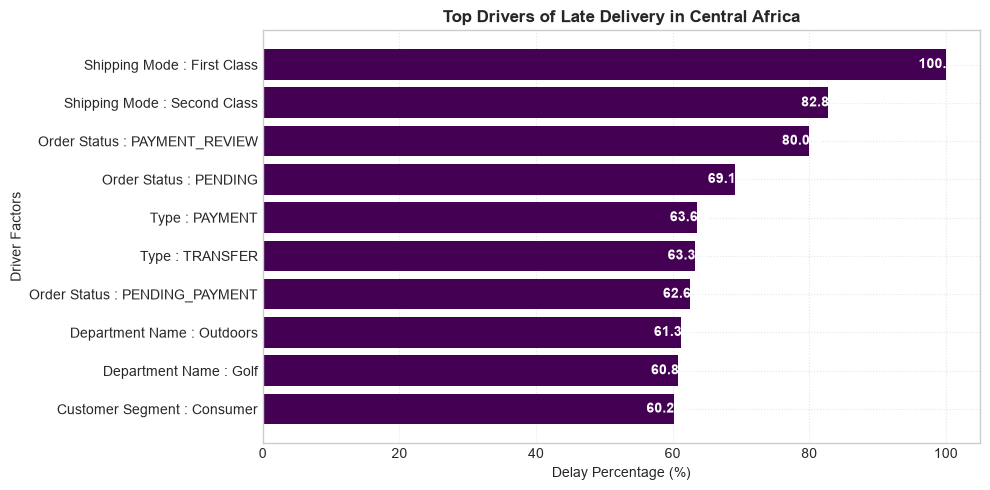

In [19]:
def top_drivers_for_region(region):
    df_region = df[df['Order Region'] == region].copy()
    drivers = ['Shipping Mode', 'Customer Segment', 'Department Name', 'Type', 'Order Status']
    all_factors = []

    for factor in drivers:
        temp = (
            df_region.groupby(factor)
            .agg(
                total_orders=('Delay', 'count'),
                late_orders=('Is_Delayed', 'sum'),
                avg_delay=('Delay', 'mean')
            )
            .reset_index()
        )
        temp['delay_pct'] = temp['late_orders'] / temp['total_orders'] * 100
        temp['Driver'] = factor
        temp['Factor_Level'] = factor + " : " + temp[factor].astype(str)
        all_factors.append(temp[['Driver', 'Factor_Level', 'delay_pct', 'avg_delay', 'total_orders']])

    final_df = pd.concat(all_factors)
    top_factors = final_df.sort_values('delay_pct', ascending=False).head(10)

    plt.figure(figsize=(10, 5))
    bars = plt.barh(top_factors['Factor_Level'], top_factors['delay_pct'], color=primary_color)
    plt.xlabel("Delay Percentage (%)")
    plt.ylabel("Driver Factors")
    plt.title(f"Top Drivers of Late Delivery in {region}", fontsize=12, fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.gca().invert_yaxis()

    for bar in bars:
        width = bar.get_width()
        plt.text(
            width - 4,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va='center',
            fontsize=10,
            color='white',
            fontweight='bold'
        )
    plt.tight_layout()
    plt.show()

# Run for Central Africa
top_drivers_for_region('Central Africa')

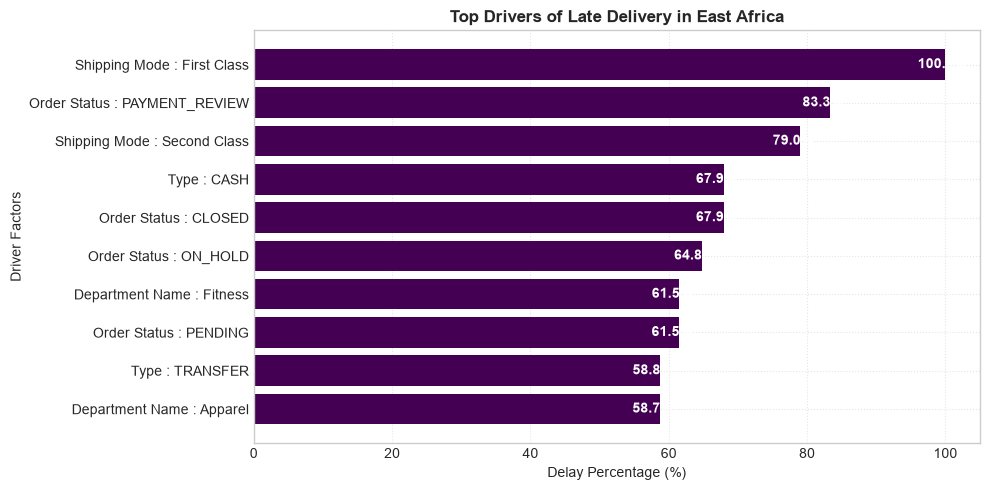

In [20]:
# Run for East Africa
top_drivers_for_region('East Africa')

## 8. Temporal & Seasonality Analysis
Analyze delay patterns across months of the year, days of the week, and hours of order placement.

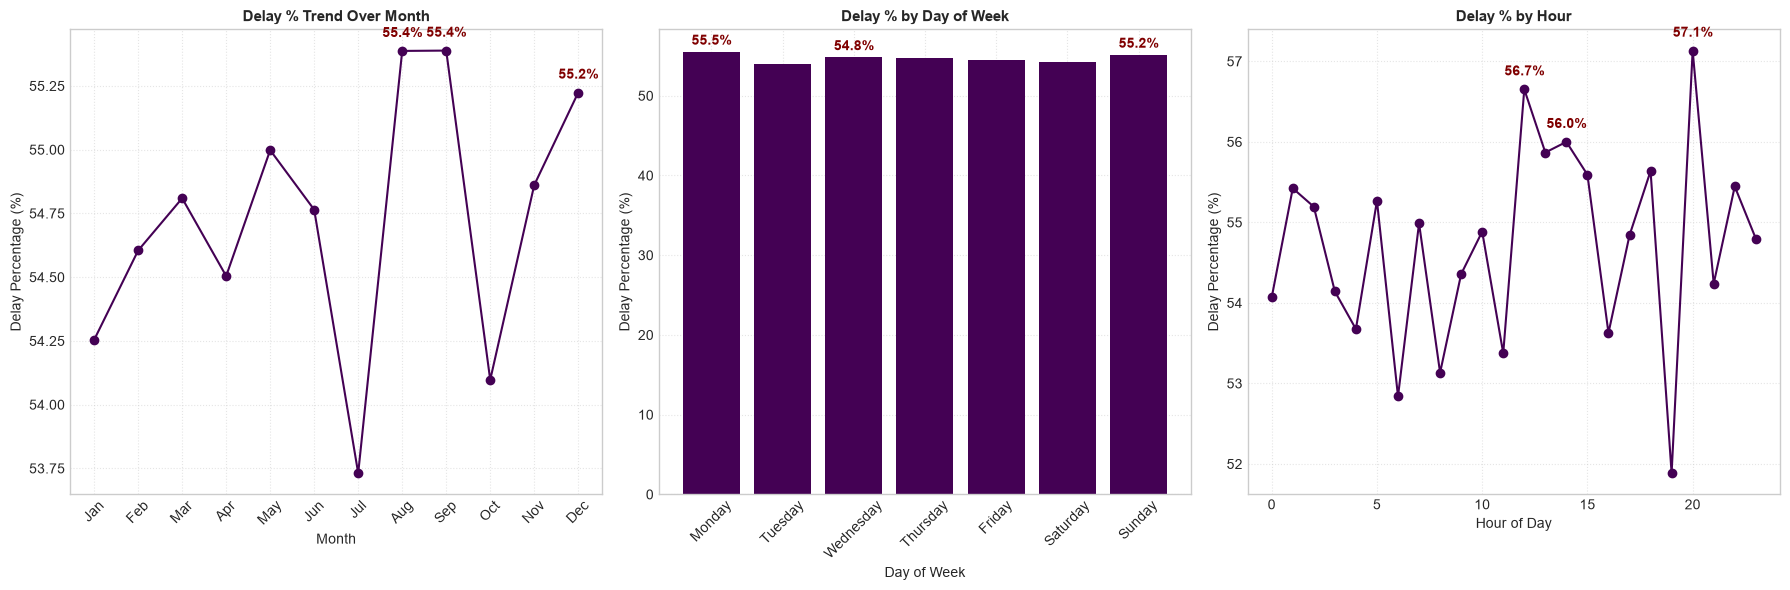

In [21]:
delay_by_month = df.groupby('order_month')['Is_Delayed'].mean().reset_index()
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100

delay_by_day = df.groupby('order_day')['Is_Delayed'].mean().reset_index()
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100

delay_by_hour = df.groupby('order_hour')['Is_Delayed'].mean().reset_index()
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Subplot 1: Month
ax1.plot(delay_by_month['order_month'], delay_by_month['delay_pct'], marker='o', color=primary_color)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month", fontsize=11, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.5)

top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(
        f"{row['delay_pct']:.1f}%",
        (row['order_month'], row['delay_pct']),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=10,
        color=danger_color,
        fontweight='bold'
    )

# Subplot 2: Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
delay_by_day['order_day'] = pd.Categorical(delay_by_day['order_day'], categories=day_order, ordered=True)
delay_by_day = delay_by_day.sort_values('order_day')

ax2.bar(delay_by_day['order_day'], delay_by_day['delay_pct'], color=primary_color)
ax2.set_xticklabels(delay_by_day['order_day'], rotation=45)
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay Percentage (%)")
ax2.set_title("Delay % by Day of Week", fontsize=11, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.5)

top3_day = delay_by_day.nlargest(3, 'delay_pct')
for _, row in top3_day.iterrows():
    height = row['delay_pct']
    ax2.text(row['order_day'], height + 0.5, f"{height:.1f}%", ha='center', va='bottom', fontsize=10, color=danger_color, fontweight='bold')

# Subplot 3: Hour
ax3.plot(delay_by_hour['order_hour'], delay_by_hour['delay_pct'], marker='o', color=primary_color)
ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour", fontsize=11, fontweight='bold')
ax3.grid(True, linestyle=':', alpha=0.5)

top3_hour = delay_by_hour.nlargest(3, 'delay_pct')
for _, row in top3_hour.iterrows():
    ax3.annotate(
        f"{row['delay_pct']:.1f}%",
        (row['order_hour'], row['delay_pct']),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=10,
        color=danger_color,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

## 9. Machine Learning: Pre-Dispatch SLA Risk Prediction
Build an automated classifier to predict `Late_delivery_risk` at checkout using pre-fulfillment attributes.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

# Select pre-fulfillment features available at checkout
X = df[[
    'Type',
    'Days for shipment (scheduled)',
    'Category Name',
    'Customer Segment',
    'Department Name',
    'Order Region',
    'Shipping Mode',
    'order_month',
    'order_hour'
]].copy()

y = df['Late_delivery_risk']

print("Feature Matrix Shape:", X.shape)
print("Target Distribution:")
print(y.value_counts())

Feature Matrix Shape: (172765, 9)
Target Distribution:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64


In [23]:
# Identify categorical features
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print('Categorical columns:', cat_cols)

# Frequency encoding for high-cardinality robustness
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X[f'{col}_freq'] = X[col].map(freq)

# Drop raw string columns
X_encoded = X.drop(columns=cat_cols)
print('Shape after frequency encoding:', X_encoded.shape)

# Train/Test Split (80/20 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']
Shape after frequency encoding: (172765, 9)


In [24]:
# Balancing the training dataset using SMOTE
print("Class distribution before balancing (train):", Counter(y_train))
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
print("Class distribution after balancing (train): ", Counter(y_train_bal))

Class distribution before balancing (train): Counter({1: 79182, 0: 59030})


Class distribution after balancing (train):  Counter({0: 79182, 1: 79182})


In [25]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n=================== {model_name} ===================")
    print("Accuracy: ", round(accuracy_score(y_true, y_pred), 2))
    print("Precision:", round(precision_score(y_true, y_pred), 2))
    print("Recall:   ", round(recall_score(y_true, y_pred), 2))
    print("\nClassification Report:\n", classification_report(y_true, y_pred))

In [26]:
# Fit Random Forest classifier on balanced training data
rf_model_balanced = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_model_balanced.fit(X_train_bal, y_train_bal)

# Predict on holdout test set
y_pred_rf_balanced = rf_model_balanced.predict(X_test)

# Evaluate performance
evaluate_model(y_test, y_pred_rf_balanced, "Random Forest (Balanced via SMOTE)")


=================== Random Forest (Balanced via SMOTE) ===================
Accuracy:  0.74
Precision: 0.78
Recall:    0.75

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.72      0.70     14758
           1       0.78      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553



## 10. Analytical Summary & Key Findings

The analysis evaluated **172,765 fulfillment orders** spanning **January 2015 through January 2018**, identifying systemic bottlenecks and measuring financial leakage:

1. **Systemic Late Delivery Rate (54.71%)**: Over half of all orders breached delivery promises, risking **$2.06M in order profit** on delayed orders alone (out of $7.5M total profit).
2. **Predictable Lead-Time Buffer (P90 = 3 Days)**: 90% of all delayed orders arrived within **3 days** of scheduled delivery, proving delays are process-driven and bufferable rather than catastrophic.
3. **Shipping Mode Is the #1 Driver**:
   - **First Class**: **100.0% delay rate** (26,513 of 26,513 orders late).
   - **Second Class**: **79.8% delay rate** (26,987 of 33,806 orders late).
   - **Standard Class**: **39.8% delay rate** (41,023 of 103,153 orders late).
   - **Same Day**: **0.0% delay rate** (0 of 9,293 orders late).
   *The mode assignment and scheduled transit promise logic are the single most critical friction points.*
4. **Regional Corridor Inefficiencies**: Central Africa (59.8%) and East Africa (58.3%) experience the highest delay rates, with all major international regional clusters averaging 55%–59%.
5. **Customer Segments Experience Equal Friction**: Consumer, Corporate, and Home Office segments experience identical delay rates (~54.7%), confirming that fulfillment issues are operational, not segment-specific.
6. **Seasonal Patterns**: Peak delay months occur in **August & September (55.4%)** and **December (55.2%)**, while July represents the lowest delay point (53.7%).
7. **Predictive Capability**: The Random Forest model achieved **74% Accuracy** and **78% Precision** in flagging at-risk orders prior to dispatch.

## 11. Concrete Business Recommendations

1. **Immediately Audit Carrier SLAs for First Class & Second Class**:
   First Class (100% late) and Second Class (79.8% late) directly violate their brand promises. Audit 3PL contracts immediately, re-calibrate promised transit days, or suspend First Class until carrier performance is resolved.
2. **Deploy the Pre-Dispatch Predictive Alert System**:
   Integrate the trained Random Forest classifier into the Order Management System (OMS). Orders flagged as high-risk ($p > 0.50$) should trigger priority warehouse queueing, carrier tier upgrades, or proactive customer notifications.
3. **Resolve Payment Processing Bottlenecks**:
   Orders held in `PAYMENT_REVIEW` and `PENDING_PAYMENT` show elevated delay rates (~55.3%). Introduce automated escalation workflows for transactions pending payment verification over 2 hours.
4. **Develop Surge Capacity Playbooks for Peak Months**:
   August, September, and December experience the highest delay rates. Build pre-season logistics capacity plans, preposition inventory in regional dark stores, and dynamically adjust checkout promise dates.
5. **Default Eligible Shipments to Standard Class**:
   Standard Class achieves a 39.8% delay rate—dramatically outperforming First and Second Class. Re-engineer checkout carrier routing to default eligible shipments to Standard Class in corridors with poor premium carrier reliability.